
# CODEALPHA DATA ANALYTICS INTERNSHIP

## TASK 2: EXPLORATORY DATA ANALYSIS

### Project Title: Bike Sharing Dataset Analysis

**Internship Domain:** Data Analytics

### Project Objective
The objective of this project is to analyze bike-sharing
data to identify rental patterns, trends and relationships
between bike demand, weather conditions and seasonal factors.

### Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook


In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("CodeAlpha Task 2 - EDA")
print("Libraries imported successfully!")


CodeAlpha Task 2 - EDA
Libraries imported successfully!



# 1. DATA LOADING AND DATA CLEANING

## 1.1 Introduction

Data cleaning is an important step in the data analysis process.
It helps ensure that the dataset is accurate, consistent and
suitable for further analysis.

In this project, the Bike Sharing dataset is examined to identify
missing values, duplicate records, incorrect data types and
inconsistent values.

## 1.2 Objectives

- Load the original Bike Sharing dataset.
- Inspect the dataset structure.
- Identify missing values.
- Detect duplicate records.
- Convert date columns into the correct format.
- Check data consistency and invalid values.
- Prepare a cleaned dataset for further analysis.


In [2]:

# ==========================================
# 1. DATA LOADING
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load original dataset
df_raw = pd.read_csv("hour.csv")

# Create a working copy
df = df_raw.copy()

print("Dataset loaded successfully!")

print("Original dataset shape:", df.shape)

# Display first five records
display(df.head())


Dataset loaded successfully!
Original dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



## 1.3 Dataset Quality Inspection

Before cleaning the dataset, we examine its structure,
column names, data types, missing values and duplicate records.

This helps us understand the quality of the original data
and identify areas that require preparation.


In [3]:

# ==========================================
# 2. DATA QUALITY INSPECTION
# ==========================================

# Dataset information
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

# Check duplicate IDs
print("\nDUPLICATE INSTANT IDs:")
print(df['instant'].duplicated().sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

MISSING VALUES
instant      


## 1.4 Handling Missing Values and Duplicate Records

Missing values and duplicate records can affect the accuracy
of data analysis.

The dataset is checked for these issues. If duplicates are
found, they will be removed. Missing values will be reviewed
before deciding on an appropriate treatment.

Since the initial inspection found no missing values or
duplicate records, unnecessary data removal or imputation
will be avoided.


In [4]:

# ==========================================
# 3. HANDLE MISSING VALUES AND DUPLICATES
# ==========================================

# Remove duplicate rows if present
before_duplicates = len(df)

df = df.drop_duplicates().copy()

removed_duplicates = before_duplicates - len(df)

print("Duplicate rows removed:", removed_duplicates)

# Check missing values
missing_before = df.isnull().sum().sum()

print("Missing values before treatment:", missing_before)

# Check missing values by column
missing_summary = df.isnull().sum()

print("\nMissing values by column:")
print(missing_summary[missing_summary > 0])

# We will not fill missing values unnecessarily.
# If missing values exist, investigate them before treatment.

print("\nMissing values after inspection:", df.isnull().sum().sum())
print("Dataset shape after duplicate removal:", df.shape)


Duplicate rows removed: 0
Missing values before treatment: 0

Missing values by column:
Series([], dtype: int64)

Missing values after inspection: 0
Dataset shape after duplicate removal: (17379, 17)



## 1.5 Data Type Conversion

The date column is initially stored as an object (text) data type.

For accurate date-based analysis, it is converted into
a datetime format.

This allows us to extract useful information such as
the month, day and year for further exploration.


In [5]:

# ==========================================
# 4. DATA TYPE CONVERSION
# ==========================================

# Convert date column to datetime
df['dteday'] = pd.to_datetime(
    df['dteday'],
    errors='coerce'
)

# Check conversion
print("Date column data type:")
print(df['dteday'].dtype)

# Create readable season labels
season_map = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

df['season_name'] = df['season'].map(season_map)

# Create readable weather labels
weather_map = {
    1: 'Clear',
    2: 'Mist/Cloudy',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
}

df['weather_name'] = df['weathersit'].map(weather_map)

# Create readable year labels
year_map = {
    0: '2011',
    1: '2012'
}

df['year_name'] = df['yr'].map(year_map)

# Create additional date features
df['day_name'] = df['dteday'].dt.day_name()
df['month_name'] = df['dteday'].dt.month_name()

print("\nNew columns created successfully!")

display(
    df[['dteday', 'season_name',
        'weather_name', 'year_name',
        'day_name', 'month_name']].head()
)


Date column data type:
datetime64[ns]

New columns created successfully!


,dteday,season_name,weather_name,year_name,day_name,month_name
0,2011-01-01,Spring,Clear,2011,Saturday,January
1,2011-01-01,Spring,Clear,2011,Saturday,January
2,2011-01-01,Spring,Clear,2011,Saturday,January
3,2011-01-01,Spring,Clear,2011,Saturday,January
4,2011-01-01,Spring,Clear,2011,Saturday,January



## 1.6 Data Consistency and Validation

Data consistency checks are performed to ensure that
the values follow the expected dataset definitions.

The following checks are conducted:

- Verify that total rentals equal casual plus registered rentals.
- Check that rental counts are non-negative.
- Check the valid ranges of categorical variables.
- Identify invalid or missing date values.

These checks help ensure that the dataset is reliable
before conducting statistical analysis.


In [6]:

# ==========================================
# 5. DATA CONSISTENCY CHECKS
# ==========================================

# Check rental count consistency
df['count_check'] = df['casual'] + df['registered']

count_consistency = (
    df['cnt'] == df['count_check']
).all()

print("Rental count consistency:", count_consistency)

# Check negative rental values
print(
    "Negative rental counts:",
    (df['cnt'] < 0).sum()
)

# Check valid ranges for categorical variables
valid_ranges = {
    'season': [1, 2, 3, 4],
    'yr': [0, 1],
    'mnth': list(range(1, 13)),
    'hr': list(range(24)),
    'holiday': [0, 1],
    'weekday': list(range(7)),
    'workingday': [0, 1],
    'weathersit': [1, 2, 3, 4]
}

print("\nINVALID VALUES CHECK")

for column, valid_values in valid_ranges.items():
    invalid_count = (~df[column].isin(valid_values)).sum()
    print(f"{column}: {invalid_count} invalid values")

# Check date conversion failures
print(
    "\nInvalid dates:",
    df['dteday'].isnull().sum()
)

# Check missing values after feature creation
print(
    "\nTotal missing values:",
    df.isnull().sum().sum()
)


Rental count consistency: True
Negative rental counts: 0

INVALID VALUES CHECK
season: 0 invalid values
yr: 0 invalid values
mnth: 0 invalid values
hr: 0 invalid values
holiday: 0 invalid values
weekday: 0 invalid values
workingday: 0 invalid values
weathersit: 0 invalid values

Invalid dates: 0

Total missing values: 0



## 1.7 Descriptive Statistics

Descriptive statistics provide a summary of the dataset.

We examine the mean, median, standard deviation,
minimum and maximum values of the numerical variables.

This helps us understand the distribution of bike rentals
and the characteristics of the dataset.


In [7]:

# ==========================================
# 6. DESCRIPTIVE STATISTICS
# ==========================================

# Summary of numerical columns
display(df.describe())

# Median values
print("\nMEDIAN VALUES")
display(df.select_dtypes(include=np.number).median())

# Rental statistics
print("\nBIKE RENTAL STATISTICS")

print("Average hourly rentals:", round(df['cnt'].mean(), 2))
print("Median hourly rentals:", df['cnt'].median())
print("Maximum hourly rentals:", df['cnt'].max())
print("Minimum hourly rentals:", df['cnt'].min())
print("Total bike rentals:", df['cnt'].sum())


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,count_check
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599,181.387599



MEDIAN VALUES


instant        8690.0000
season            3.0000
yr                1.0000
mnth              7.0000
hr               12.0000
holiday           0.0000
weekday           3.0000
workingday        1.0000
weathersit        1.0000
temp              0.5000
atemp             0.4848
hum               0.6300
windspeed         0.1940
casual           17.0000
registered      115.0000
cnt             142.0000
count_check     142.0000
dtype: float64


BIKE RENTAL STATISTICS
Average hourly rentals: 189.46
Median hourly rentals: 142.0
Maximum hourly rentals: 977
Minimum hourly rentals: 1
Total bike rentals: 3292679



## 1.8 Saving the Cleaned Dataset

After completing the data cleaning and validation process,
the prepared dataset is saved as a new CSV file.

The original dataset remains unchanged.

The cleaned dataset will be used for subsequent
exploratory data analysis and visualization.


In [8]:

# ==========================================
# 7. SAVE CLEANED DATASET
# ==========================================

# Remove temporary validation column
df.drop(columns=['count_check'], inplace=True)

# Create output folder
output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

# Save cleaned dataset
cleaned_file = output_folder / "bike_sharing_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("DATA CLEANING COMPLETED!")
print("Final dataset shape:", df.shape)
print("Saved location:", cleaned_file.resolve())

display(df.head())


DATA CLEANING COMPLETED!
Final dataset shape: (17379, 22)
Saved location: C:\CodeAlpha\CodeAlpha_task2_EDA\outputs\bike_sharing_cleaned.csv


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_name,weather_name,year_name,day_name,month_name
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,Spring,Clear,2011,Saturday,January
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,Spring,Clear,2011,Saturday,January
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,Spring,Clear,2011,Saturday,January
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,Spring,Clear,2011,Saturday,January
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,Spring,Clear,2011,Saturday,January



# 2. DATA UNDERSTANDING

The Bike Sharing dataset contains hourly rental information
collected over two years.

This section examines the variables, data types and
overall characteristics of the dataset.


In [9]:

# Display dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display column names and types
display(
    pd.DataFrame({
        'Column': df.columns,
        'Data Type': df.dtypes.astype(str).values,
        'Unique Values': df.nunique().values
    })
)


Rows: 17379
Columns: 22


,Column,Data Type,Unique Values
0,instant,int64,17379
1,dteday,datetime64[ns],731
2,season,int64,4
3,yr,int64,2
4,mnth,int64,12
5,hr,int64,24
6,holiday,int64,2
7,weekday,int64,7
8,workingday,int64,2
9,weathersit,int64,4



# 3. EXPLORATORY DATA ANALYSIS

Exploratory Data Analysis is performed to discover
patterns, trends and relationships within the dataset.

The analysis focuses on understanding bike rental demand
based on time, seasons, weather conditions and user types.

### Research Questions

1. Which hours have the highest bike rental demand?
2. Which season has the highest average rentals?
3. How does weather affect bike rental demand?
4. Are bike rentals higher on working days or non-working days?
5. How do registered and casual users differ?
6. How did bike rental demand change between 2011 and 2012?



## 3.1 Hourly Bike Rental Analysis

This analysis identifies the hours with the highest
and lowest average bike rental demand.

It helps us understand daily usage patterns.


In [10]:

hourly_rentals = df.groupby('hr')['cnt'].mean()

print("Average rentals by hour:")
display(hourly_rentals)

print("Peak rental hour:", hourly_rentals.idxmax())
print("Lowest rental hour:", hourly_rentals.idxmin())
print("Maximum average rentals:", round(hourly_rentals.max(), 2))


Average rentals by hour:


hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

Peak rental hour: 17
Lowest rental hour: 4
Maximum average rentals: 461.45



## 3.2 Seasonal Bike Rental Analysis

This analysis compares average bike rentals across
the four seasons to identify seasonal demand patterns.


In [11]:

season_rentals = (
    df.groupby('season_name')['cnt']
    .mean()
    .sort_values(ascending=False)
)

print("Average rentals by season:")
display(season_rentals)

print("Highest demand season:", season_rentals.idxmax())


Average rentals by season:


season_name
Fall      236.016237
Summer    208.344069
Winter    198.868856
Spring    111.114569
Name: cnt, dtype: float64

Highest demand season: Fall



## 3.3 Weather and Bike Rental Analysis

Weather conditions can influence people's willingness
to use bike-sharing services.

This section compares average rentals across
different weather conditions.


In [12]:

weather_rentals = (
    df.groupby('weather_name')['cnt']
    .mean()
    .sort_values(ascending=False)
)

print("Average rentals by weather:")
display(weather_rentals)


Average rentals by weather:


weather_name
Clear              204.869272
Mist/Cloudy        175.165493
Light Rain/Snow    111.579281
Heavy Rain/Snow     74.333333
Name: cnt, dtype: float64


## 3.4 Working Day Analysis

This analysis compares average bike rentals on
working days and non-working days.

It helps identify whether bike-sharing services
are primarily used for commuting or leisure.


In [13]:

workingday_map = {
    0: 'Non-Working Day',
    1: 'Working Day'
}

df['workingday_name'] = df['workingday'].map(workingday_map)

workingday_rentals = (
    df.groupby('workingday_name')['cnt']
    .mean()
)

print("Average rentals by working-day type:")
display(workingday_rentals)


Average rentals by working-day type:


workingday_name
Non-Working Day    181.405332
Working Day        193.207754
Name: cnt, dtype: float64


## 3.5 User Type Analysis

This section compares casual and registered bike-sharing users.

The purpose is to understand which user group contributes
more to total bike rental demand.


In [14]:

user_summary = pd.Series({
    'Casual Users': df['casual'].sum(),
    'Registered Users': df['registered'].sum()
})

print("Total rentals by user type:")
display(user_summary)

print(
    "Registered user percentage:",
    round(df['registered'].sum() / df['cnt'].sum() * 100, 2),
    "%"
)

print(
    "Casual user percentage:",
    round(df['casual'].sum() / df['cnt'].sum() * 100, 2),
    "%"
)


Total rentals by user type:


Casual Users         620017
Registered Users    2672662
dtype: int64

Registered user percentage: 81.17 %
Casual user percentage: 18.83 %



## 3.6 Yearly Rental Analysis

This section compares total and average bike rentals
between 2011 and 2012.

It helps identify changes in bike-sharing demand over time.


In [15]:

yearly_rentals = (
    df.groupby('year_name')
    .agg(
        total_rentals=('cnt', 'sum'),
        average_hourly_rentals=('cnt', 'mean')
    )
)

print("Yearly rental comparison:")
display(yearly_rentals)


Yearly rental comparison:


,total_rentals,average_hourly_rentals
year_name,,
2011,1243103,143.794448
2012,2049576,234.666361



# 4. DATA VISUALIZATION

Data visualization helps communicate findings
through charts and graphs.

In this section, Matplotlib and Seaborn are used
to create visual representations of bike rental patterns.


In [16]:

# Visualization settings

sns.set_theme(style="whitegrid")

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Create folder for charts
chart_folder = Path("outputs/charts")
chart_folder.mkdir(parents=True, exist_ok=True)

print("Visualization environment ready!")


Visualization environment ready!


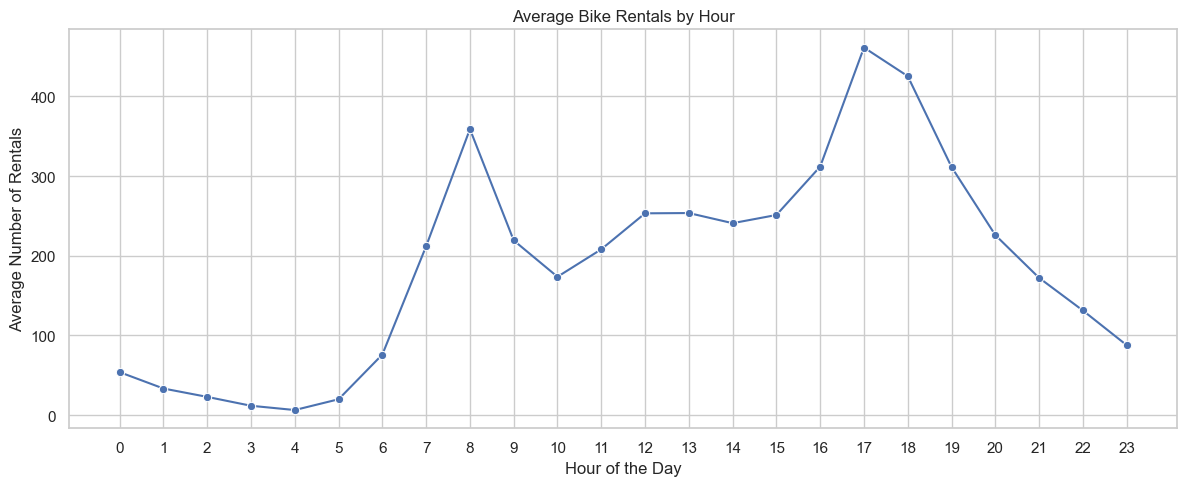

In [17]:

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_rentals.index,
    y=hourly_rentals.values,
    marker='o'
)

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')
plt.xticks(range(24))
plt.tight_layout()

plt.savefig(chart_folder / 'hourly_rentals.png', dpi=300)
plt.show()


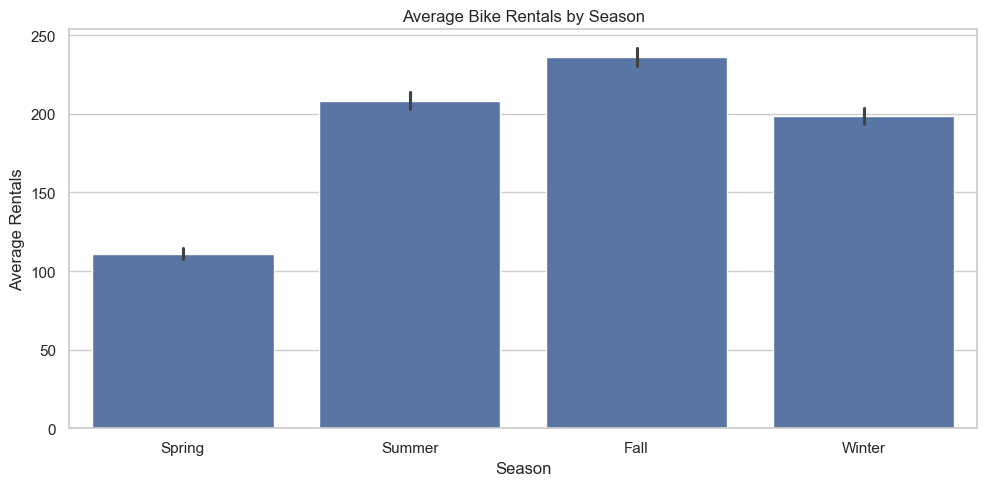

In [18]:

season_order = ['Spring', 'Summer', 'Fall', 'Winter']

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='season_name',
    y='cnt',
    order=season_order,
    estimator='mean'
)

plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Rentals')
plt.tight_layout()

plt.savefig(chart_folder / 'seasonal_rentals.png', dpi=300)
plt.show()


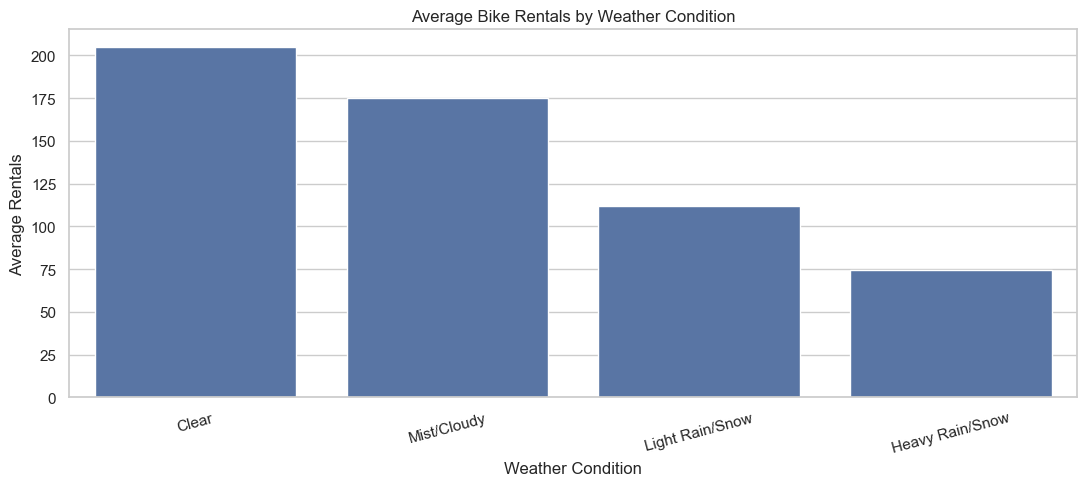

In [19]:

plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x='weather_name',
    y='cnt',
    estimator='mean',
    errorbar=None
)

plt.title('Average Bike Rentals by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Rentals')
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(chart_folder / 'weather_rentals.png', dpi=300)
plt.show()


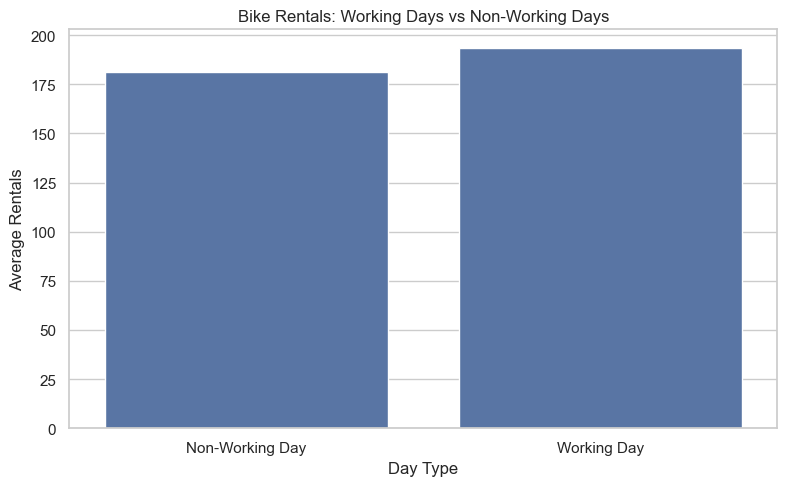

In [20]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='workingday_name',
    y='cnt',
    estimator='mean',
    errorbar=None
)

plt.title('Bike Rentals: Working Days vs Non-Working Days')
plt.xlabel('Day Type')
plt.ylabel('Average Rentals')
plt.tight_layout()

plt.savefig(chart_folder / 'workingday_comparison.png', dpi=300)
plt.show()


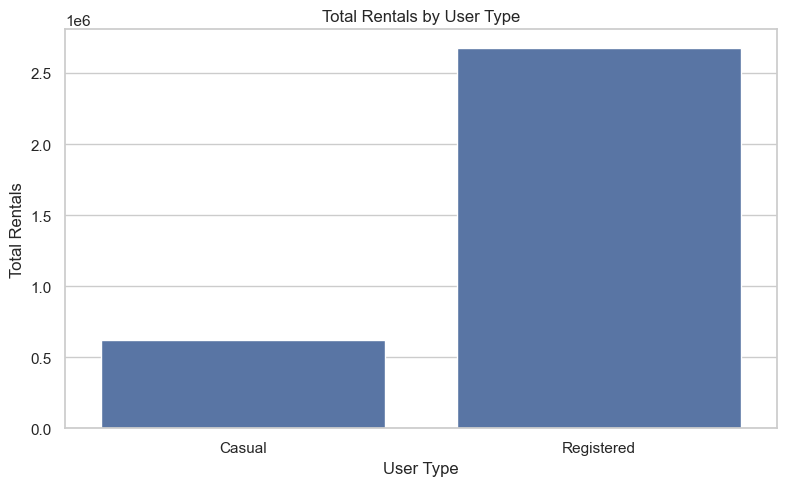

In [21]:

user_plot = pd.DataFrame({
    'User Type': ['Casual', 'Registered'],
    'Total Rentals': [
        df['casual'].sum(),
        df['registered'].sum()
    ]
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=user_plot,
    x='User Type',
    y='Total Rentals'
)

plt.title('Total Rentals by User Type')
plt.xlabel('User Type')
plt.ylabel('Total Rentals')

plt.tight_layout()
plt.savefig(chart_folder / 'user_type_comparison.png', dpi=300)
plt.show()


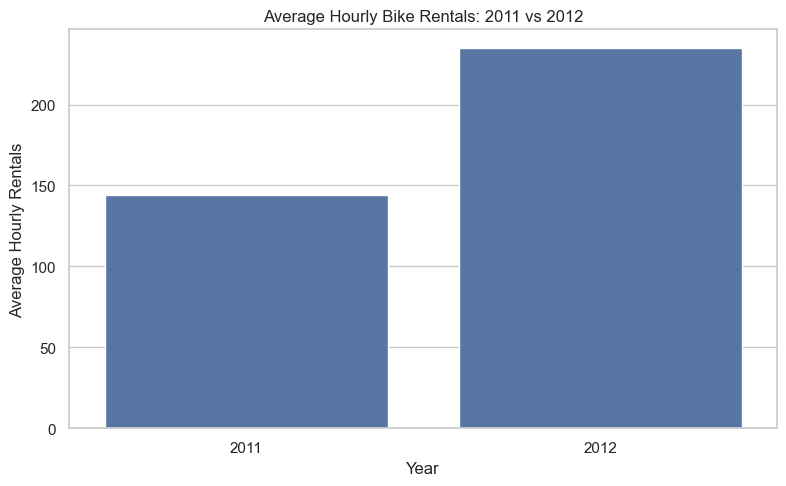

In [22]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='year_name',
    y='cnt',
    estimator='mean',
    errorbar=None
)

plt.title('Average Hourly Bike Rentals: 2011 vs 2012')
plt.xlabel('Year')
plt.ylabel('Average Hourly Rentals')

plt.tight_layout()
plt.savefig(chart_folder / 'yearly_comparison.png', dpi=300)
plt.show()



# 5. CORRELATION ANALYSIS

Correlation analysis is used to examine the relationships
between numerical variables.

The analysis focuses on temperature, humidity,
wind speed and total bike rentals.

Correlation indicates association and does not
necessarily establish causation.


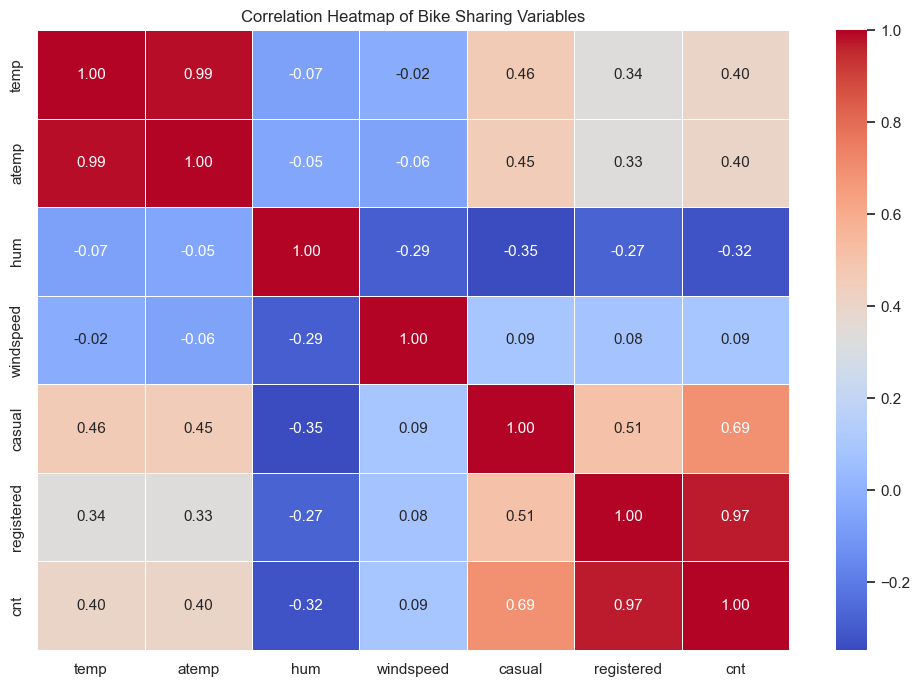

Correlation with total bike rentals:


cnt           1.000000
registered    0.972151
casual        0.694564
temp          0.404772
atemp         0.400929
windspeed     0.093234
hum          -0.322911
Name: cnt, dtype: float64

In [23]:

correlation_columns = [
    'temp', 'atemp', 'hum',
    'windspeed', 'casual',
    'registered', 'cnt'
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Bike Sharing Variables')
plt.tight_layout()

plt.savefig(chart_folder / 'correlation_heatmap.png', dpi=300)
plt.show()

print("Correlation with total bike rentals:")
display(
    correlation_matrix['cnt'].sort_values(ascending=False)
)



# 6. KEY FINDINGS AND INSIGHTS

This section summarizes the main findings obtained
from exploratory data analysis.

The findings focus on hourly demand, seasonal patterns,
weather conditions, user types and yearly changes.


In [24]:

# ==========================================
# KEY FINDINGS
# ==========================================

peak_hour = hourly_rentals.idxmax()
low_hour = hourly_rentals.idxmin()

best_season = season_rentals.idxmax()
best_weather = weather_rentals.idxmax()

best_workingday = workingday_rentals.idxmax()

highest_user = user_summary.idxmax()

print("=" * 50)
print("BIKE SHARING DATA ANALYSIS - KEY FINDINGS")
print("=" * 50)

print(f"\n1. Peak rental hour: {peak_hour}:00")
print(f"2. Lowest rental hour: {low_hour}:00")
print(f"3. Highest demand season: {best_season}")
print(f"4. Highest average rentals by weather: {best_weather}")
print(f"5. Higher rental day type: {best_workingday}")
print(f"6. Largest user group: {highest_user}")

print("\n7. Yearly rental comparison:")
display(yearly_rentals)

print("\n8. User type distribution:")
display(user_summary)

print("=" * 50)


BIKE SHARING DATA ANALYSIS - KEY FINDINGS

1. Peak rental hour: 17:00
2. Lowest rental hour: 4:00
3. Highest demand season: Fall
4. Highest average rentals by weather: Clear
5. Higher rental day type: Working Day
6. Largest user group: Registered Users

7. Yearly rental comparison:


,total_rentals,average_hourly_rentals
year_name,,
2011,1243103,143.794448
2012,2049576,234.666361



8. User type distribution:


Casual Users         620017
Registered Users    2672662
dtype: int64


# 7. CONCLUSION AND RECOMMENDATIONS

## 7.1 Conclusion

This project explored the Bike Sharing dataset using
Python and exploratory data analysis techniques.

The analysis examined hourly bike rental demand,
seasonal patterns, weather conditions, working days,
user categories and yearly rental trends.

Data visualization and statistical analysis helped
identify important patterns in bike-sharing usage.

The findings provide useful information for understanding
customer demand and improving bike-sharing operations.

## 7.2 Recommendations

Based on the findings, the following recommendations
can be considered:

1. Ensure sufficient bicycle availability during
   peak rental hours.

2. Consider seasonal demand when planning bicycle
   maintenance and distribution.

3. Monitor weather conditions when estimating
   expected rental demand.

4. Develop customer engagement strategies to
   encourage casual users to become registered users.

5. Use historical rental data to support future
   operational planning.

## 7.3 Project Limitations

- The dataset covers only 2011 and 2012.
- The analysis identifies associations rather than
  proving causal relationships.
- The findings may not represent current bike-sharing
  demand in other cities or periods.

## 7.4 Tools Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook


In [25]:

# ==========================================
# FINAL PROJECT OUTPUTS
# ==========================================

# Save final cleaned data
df.to_csv(
    output_folder / "bike_sharing_cleaned.csv",
    index=False
)

# Save summary statistics
df.describe().to_csv(
    output_folder / "descriptive_statistics.csv"
)

# Save hourly rental summary
hourly_rentals.to_csv(
    output_folder / "hourly_rental_summary.csv"
)

# Save seasonal rental summary
season_rentals.to_csv(
    output_folder / "seasonal_rental_summary.csv"
)

# Save weather rental summary
weather_rentals.to_csv(
    output_folder / "weather_rental_summary.csv"
)

# Save user summary
user_summary.to_csv(
    output_folder / "user_type_summary.csv"
)

print("====================================")
print("CODEALPHA TASK 2 COMPLETED")
print("====================================")
print("Cleaned dataset saved.")
print("Statistical summaries saved.")
print("Charts saved in outputs/charts.")
print("Project outputs generated successfully!")


CODEALPHA TASK 2 COMPLETED
Cleaned dataset saved.
Statistical summaries saved.
Charts saved in outputs/charts.
Project outputs generated successfully!
